In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "061a82116be00c585cab41d5b2a790e2a4f96d44"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/061a82116be00c585cab41d5b2a790e2a4f96d44/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Codes, Compression, and Perplexity

A model that reaches a loss of $x$ bits per symbol on a text should be able
to store that text in about $x$ bits per symbol.
that section suggested as much when it read an
entropy and a cross-entropy as average codeword lengths. It did so for one
source, whose surprisals are whole numbers of bits, and we never built a
code for any other. The claim means little until such a code exists. This
section asks two questions: is there a code whose length is a model's
log-loss, and how close do real compressors come to it?

Compressors are familiar tools, and they already suggest the answer. Take
*The Time Machine*, the novel of that section, reduced to
173,428 characters over 27 symbols, the 26 letters and the space. The
general-purpose compressor `zlib`, which replaces repeated strings by
pointers and then codes one symbol at a time, stores it in $2.84$ bits per
character. A small model that predicts each character from the three before
it, learning its counts as it reads, codes the same text in $2.55$ bits per
character. The better predictor writes the shorter file, and this section
shows why. Once a code exists whose length is the log-loss, a loss such as
the $1.2$ nats per character of the chapter introduction is a file size,
and two models can be compared by the length of the files they write.

We build the code in steps, and each step answers a question. How short can
codewords be when the receiver gets no separators between them? What does it
cost that every codeword has a whole number of bits, and can a code avoid
that cost? How short can a file of text get, where each character depends
on those before it? And what does a perplexity, the number that language
models report, say about the file? We count in bits throughout, because
codewords are binary strings; $x$ bits are $x \ln 2$ nats.

Beyond the book's standard imports, the section needs `re` to clean the text
and `zlib` as the compressor to beat.

In [1]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

In [2]:
import re
import zlib

## Symbol Codes

We start with the simplest sender. A stream of symbols, drawn independently
from a distribution $P$ over $k$ outcomes, must travel as one binary string
with no separators, and the receiver must split it back into symbols.

### Prefix Codes and the Kraft Inequality

Each outcome $i$ gets a binary string, its *codeword*, of length $\ell_i$.
The receiver can split the stream without separators if no codeword is a
prefix of another; such a code is called *prefix-free*, or a *prefix code*.
Telephone numbers work this way: once the dialed digits match a number, no
longer number starts with the same digits, so the exchange knows that the
number is complete. The code $0, 10, 110, 111$ for four symbols is
prefix-free, and the stream `110010111` splits in only one way, as
`110|0|10|111`.

![The prefix-free code $0, 10, 110, 111$ as a binary tree. Each codeword is the path from the root to a leaf (left edge $0$, right edge $1$), and no codeword continues through another. A leaf at depth $\ell$ uses up a fraction $2^{-\ell}$ of the tree, and the four leaves use up all of it, $2^{-1} + 2^{-2} + 2^{-3} + 2^{-3} = 1$. The symbols $a, b, c, d$ and the probabilities below them are those of the previous section's dyadic source.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-it-kraft-tree.svg)

the figure draws this code as a binary tree. A codeword
of length $\ell$ ends at a leaf and removes everything below it, a fraction
$2^{-\ell}$ of the tree. The fractions removed by all codewords must fit
into one tree, a budget of $1$, so short codewords are expensive. The
lengths $(1, 2, 3, 3)$ of the figure use
$\tfrac12 + \tfrac14 + \tfrac18 + \tfrac18 = 1$, the whole tree. Four
codewords of length $1$ would use $2$ trees, which is impossible: only two
strings of length one exist. The lengths $(1, 2, 4)$ use
$\tfrac12 + \tfrac14 + \tfrac1{16} = 0.8125$ and fit with room to spare,
for instance as $0, 10, 1100$.

The tree is also a strategy for the questions game of
that section. Every internal node asks a yes/no
question, and a codeword is the list of answers. With $0$ for yes, the code
$0, 10, 110, 111$ asks "Is it the first symbol?", then "the second?", then
"the third?". The previous section wrote $1$ for yes and obtained the
mirror image, $1, 01, 001, 000$
(Exercise 1).

**Proposition (Kraft inequality).** *A prefix-free binary code with
codeword lengths $\ell_1, \ldots, \ell_k$ exists if and only if*

$$
\sum_{i=1}^k 2^{-\ell_i} \leq 1.
$$

**Proof.** Identify each codeword $c$ of length $\ell$ with the half-open
interval $[0.c,\, 0.c + 2^{-\ell})$ of all real numbers in $[0, 1)$ whose
binary expansion begins with $c$. For example, the codeword $10$ owns
$[0.10_2, 0.11_2) = [\tfrac{1}{2}, \tfrac{3}{4})$, of length $2^{-2}$. In
the figure this interval is the leaf of $b$ together with
everything that the leaf removes below it. Such *dyadic* intervals are
either nested or disjoint. If $c$ is a prefix of $c'$, every number that
begins with $c'$ begins with $c$, so the intervals are nested. Otherwise
$c$ and $c'$ differ at some digit within the shorter length, no number can
begin with both, and the intervals are disjoint. A prefix-free code
therefore owns disjoint intervals inside $[0, 1)$, and their total length
$\sum_i 2^{-\ell_i}$ is at most $1$.

Conversely, let the lengths satisfy the equation. The key step is
to sort them, $\ell_1 \leq \cdots \leq \ell_k$, and to lay intervals of
length $2^{-\ell_i}$ side by side from $0$. The $i$-th interval starts at
$s_i = \sum_{m < i} 2^{-\ell_m}$ and ends at $s_i + 2^{-\ell_i} \leq 1$.
Every earlier length satisfies $\ell_m \leq \ell_i$, so each term of $s_i$
is a multiple of $2^{-\ell_i}$, and so is $s_i$. The $i$-th interval is
therefore the dyadic interval of the codeword formed by the first $\ell_i$
binary digits of $s_i$. The intervals are disjoint, so by the first part no
codeword is a prefix of another. $\blacksquare$

The budget binds more codes than the prefix-free ones. A code is *uniquely
decodable* if every concatenation of codewords parses in only one way,
prefix-free or not. McMillan showed that such codes obey the same
inequality [@McMillan.1956]
(Exercise 2). Every length
profile that a uniquely decodable code achieves, a prefix code therefore
achieves too, and restricting to prefix codes costs nothing.

### Shannon Lengths and the Entropy Bound

Given the budget, which lengths minimize the expected code length
$\mathbb{E}[\ell] = \sum_i p_i \ell_i$? Frequent symbols should get short
codewords, but a codeword of length $1$ already spends half the budget.

To see where the answer comes from, let the lengths be real numbers for a
moment. Unspent budget never helps, because shortening a codeword lowers
$\mathbb{E}[\ell]$, so at the optimum $\sum_i 2^{-\ell_i} = 1$. Lagrange's
rule for a minimum under an equality constraint says that there the
gradient of the objective is a multiple of the gradient of the constraint
(that section). The derivative of $\mathbb{E}[\ell]$ in
$\ell_i$ is $p_i$, and that of $\sum_i 2^{-\ell_i}$ is $-2^{-\ell_i}\ln 2$.
Hence $2^{-\ell_i} = c\, p_i$ for one constant $c$ and all $i$. Summing
both sides over $i$ gives $c = 1$, and the best real lengths and their
expected length are

$$
\ell_i = \log_2 \frac{1}{p_i},
\qquad
\mathbb{E}[\ell] = \sum_i p_i \log_2 \frac{1}{p_i} = H_2(P).
$$

So each symbol gets as many bits as its *surprisal* $\log_2(1/p_i)$, the
self-information of that section in bits, and the
expected length is $H_2(P)$, the entropy in bits. Real codewords need whole
bits. For the dyadic source $P = (\tfrac12, \tfrac14, \tfrac18, \tfrac18)$
the surprisals $1, 2, 3, 3$ are already integers, the code of
the figure has these lengths, and
$\mathbb{E}[\ell] = 1.75$ bits $= H_2(P)$, with nothing wasted. For
$P = (0.6, 0.3, 0.1)$, the first of the chapter's running pair of
distributions, the surprisals are $0.74$, $1.74$ and $3.32$ bits. Rounding
them up gives the *Shannon lengths* $1, 2, 4$, the profile that fit the
tree with room to spare. Its Kraft sum is $0.8125$, and
$\mathbb{E}[\ell] = 0.6 + 0.6 + 0.4 = 1.6$ bits, against
$H_2(P) = 1.295$.

Whole-bit lengths chosen with more care cannot beat the entropy, and the
Shannon lengths never land more than one bit above it. Both statements rest
on one fact from that section, the decomposition of
the cross-entropy, which we restate in bits; the subscript $2$ and the
superscript $(2)$ mark base-$2$ logarithms. The expected log-loss of a
model $Q$ on data from $P$, the cross-entropy, splits into the entropy of
the data and the Kullback–Leibler divergence,

$$
\textrm{CE}_2(P, Q) = -\sum_i p_i \log_2 q_i
= H_2(P) + D_{\textrm{KL}}^{(2)}(P \| Q),
\qquad D_{\textrm{KL}}^{(2)}(P \| Q) \geq 0,
$$

where the last inequality is Gibbs': no model beats the entropy of the
data, and only $Q = P$ reaches it. For the running pair, the $P$ above and
$Q = (0.2, 0.5, 0.3)$, the three terms are $1.867 = 1.295 + 0.571$ bits, up
to rounding in the last digit.

**Proposition (entropy bounds the code length).** *Let $P$ have all
$p_i > 0$ (symbols of probability zero need no codeword). Every
prefix-free binary code has $\mathbb{E}[\ell] \geq H_2(P)$, with equality
if and only if every $p_i$ equals $2^{-\ell_i}$. The* Shannon code *with
lengths $\ell_i = \lceil \log_2 (1/p_i) \rceil$ is prefix-free and has
$\mathbb{E}[\ell] < H_2(P) + 1$.*

**Proof.** For the lower bound, compare the code with the distribution it
implies. Let $Z = \sum_i 2^{-\ell_i}$, which is at most $1$ by Kraft, and
let $q_i = 2^{-\ell_i}/Z$. Then $\ell_i = -\log_2 q_i - \log_2 Z$, and
averaging under $P$ gives

$$
\mathbb{E}[\ell] = \sum_i p_i \ell_i
= -\sum_i p_i \log_2 q_i - \log_2 Z
= H_2(P) + D_{\textrm{KL}}^{(2)}(P \| Q) - \log_2 Z
\geq H_2(P).
$$

The inequality holds because the KL term is never negative and
$-\log_2 Z \geq 0$. Equality needs both to vanish: $Q = P$ and $Z = 1$,
that is, $p_i = 2^{-\ell_i}$. For the upper bound, the Shannon lengths
satisfy $2^{-\ell_i} \leq p_i$, so they pass Kraft's test
($\sum_i 2^{-\ell_i} \leq \sum_i p_i = 1$) and a prefix code with these
lengths exists. Each length is less than $\log_2(1/p_i) + 1$, and averaging
gives $\mathbb{E}[\ell] < H_2(P) + 1$. $\blacksquare$

The identity the equation is worth more than the bound
it proves. A code can waste bits in only two ways: by implying a
distribution $Q$ other than $P$, and by leaving budget unspent. For the
running $P$ the Shannon code wastes $1.6 - 1.295 = 0.305$ bits, of which
$0.005$ is mismatch and $0.300$ is unspent budget (Exercise
4).

The proposition places the best expected length of a symbol code between
$H_2(P)$ and $H_2(P) + 1$ bits. This is the bound on the number of yes/no
questions that that section promised. The best
length equals the entropy only when every probability is a power of
$\tfrac12$.

How much of the one bit can a better code recover? Huffman's algorithm
[@Huffman.1952] builds the best symbol code by merging the two least
probable symbols into one, again and again (Exercise
3), and it is the symbol code
inside `zlib`. For the running $P$ it finds the lengths $1, 2, 2$ and spends
$1.4$ bits, only $0.1$ above the entropy, so two thirds of the Shannon
code's waste was avoidable. But no codeword is shorter than one bit, and for
a skewed source that is nearly the whole of the allowed slack.

Take a source that emits the symbol `a` with probability $0.9$ and the
symbol `b` with probability $0.1$. Its entropy is $0.47$ bits per symbol,
and each `a` carries only $\log_2(1/0.9) = 0.15$ bits of surprise. Yet
every symbol code spends a whole bit on an `a`, more than six times its
information. At probability $0.999$ the entropy is $0.011$ bits per symbol,
and the cost is still $1$. The "$+1$" is the cost of coding one symbol at a
time. Coding blocks of symbols shrinks it. A block of $n$ symbols is one
symbol of a larger alphabet, and its code rounds up once for the whole
block, so the slack per original symbol is below $1/n$. Huffman's code for
pairs of `a`/`b` symbols already spends only $0.645$ bits per symbol.

### Mismatched Codes and Cross-Entropy

In practice the code is built from a model $Q$, and the data come from $P$.
The Shannon code for $Q$ has lengths $\ell_i = \lceil \log_2 (1/q_i)
\rceil$, which requires $q_i > 0$ for every symbol that $P$ can produce. On
data from $P$ its expected length satisfies

$$
\textrm{CE}_2(P, Q) \;\leq\; \mathbb{E}_P[\ell] \;<\; \textrm{CE}_2(P, Q) + 1,
$$

because termwise $\log_2(1/q_i) \leq \ell_i < \log_2(1/q_i) + 1$, and we
average under $P$. Cross-entropy is therefore the length of a code built
from the model, to within one bit, and by the equation the KL
divergence is the extra length over the code built from the truth.

The cell builds the Shannon code of a distribution `q`, averages its lengths
under the data distribution `p`, and prints the Kraft sum and the
cross-entropy next to the result. It does so for the two sources of this
section, each with its own code and with a mismatched one: the dyadic source
with the code of the uniform distribution, and the running $P$ with the code
of $Q = (0.2, 0.5, 0.3)$.

In [3]:
def shannon_lengths(q):
    return [math.ceil(math.log2(1 / q_i)) for q_i in q]

def code_report(name, p, q):
    """The Shannon code built from q, used on data from p (all in bits)."""
    ells = shannon_lengths(q)
    kraft = sum(2 ** -ell for ell in ells)
    avg = sum(p_i * ell for p_i, ell in zip(p, ells))
    ce2 = -sum(p_i * math.log2(q_i) for p_i, q_i in zip(p, q))
    print(f'{name:<16} lengths {ells}  Kraft {kraft:.4f}  '
          f'E[ell] {avg:.3f}  CE2 {ce2:.3f}')

dyadic, uniform = [1/2, 1/4, 1/8, 1/8], [1/4] * 4
p, q = [0.6, 0.3, 0.1], [0.2, 0.5, 0.3]
code_report('dyadic, own', dyadic, dyadic)
code_report('dyadic, uniform', dyadic, uniform)
code_report('P, own', p, p)
code_report('P, code from Q', p, q)

dyadic, own      lengths [1, 2, 3, 3]  Kraft 1.0000  E[ell] 1.750  CE2 1.750
dyadic, uniform  lengths [2, 2, 2, 2]  Kraft 1.0000  E[ell] 2.000  CE2 2.000
P, own           lengths [1, 2, 4]  Kraft 0.8125  E[ell] 1.600  CE2 1.295
P, code from Q   lengths [3, 1, 2]  Kraft 0.8750  E[ell] 2.300  CE2 1.867


The two rows with a matched code repeat the hand calculations: there the
column `CE2` is the entropy, and the expected lengths are $1.75$ and $1.6$
bits. The mismatched rows are new. The code built from $Q$ has lengths
$3, 1, 2$, so the most frequent symbol of $P$ gets the longest codeword. On
data from $P$ it averages $2.3$ bits, inside the window
$1.867 \leq 2.3 < 2.867$ of the equation. The uniform
code spends two bits on every symbol of the dyadic source. Nothing is
rounded there, so the lower bound holds with equality, and
$2.0 = 1.75 + 0.25$ bits is the matched length plus a KL divergence of
$0.25$ bits. The Kraft column shows which codes leave budget unspent: none
for the dyadic source, $0.1875$ for the Shannon code of $P$, and $0.125$
for the code from $Q$.

The bound the equation covers the Shannon code of $Q$,
not every code someone might build from $Q$. Huffman's code for $Q$ has
lengths $2, 1, 2$, spends the whole budget, and costs
$1.2 + 0.3 + 0.2 = 1.7 < 1.867$ bits on data from $P$. Its implied
distribution is $(\tfrac14, \tfrac12, \tfrac14)$, not $Q$, and it happens
to be closer to $P$. By the equation the waste of a
code depends on the distribution it implies, and $Q$ enters only through the
lengths it suggests.

## Stream Codes and Description Length

A symbol code rounds once per symbol. We now build a code that rounds once
per message, let a language model drive it, and then ask what the model
itself costs to send.

### Arithmetic Coding

Blocks remove the rounding loss, but they need a table. A code for blocks of
$100$ binary symbols has $2^{100}$ codewords, more than any computer can
store. What we want is the length of the block code without its table: one
codeword for the whole message, computed from the message itself. A code of
this kind is a *stream code*. *Arithmetic coding*
[@Rissanen.1976; @Witten.Neal.Cleary.1987] is the standard stream code.
It represents the message as an interval.
the figure shows it on the message `aaaaaaaaba`, ten
symbols from the skewed source above that emits `a` with probability $0.9$,
coded with the true model.

![Arithmetic coding of the message aaaaaaaaba under the model $q(\texttt{a}) = 0.9$. (a) Each symbol keeps the slice of the current interval that the model assigns to it; after ten symbols the interval has width $w = 0.9^9 \cdot 0.1 = 0.0387$, the probability of the message. (b) The final interval is named by a dyadic interval inside it. Neither dyadic interval of length $2^{-5}$ that meets it fits inside, but the one of length $2^{-6}$ from $0.390625$ to $0.40625$ does, so the codeword is its address 011001: six bits for a message of $4.69$ bits of surprisal.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-it-arith-intervals.svg)

The coder keeps a current interval, initially $[0, 1)$. To encode the next
symbol it splits the current interval into one slice per possible symbol,
with widths proportional to the model's conditional probabilities
$q(\cdot \mid x_{<i})$, and keeps the slice of the symbol that occurred.
Each step multiplies the width by the probability of the observed symbol,
so after the message $x_1, \ldots, x_n$ the interval has width

$$
w = \prod_{i=1}^n q(x_i \mid x_{<i}),
$$

the probability that the model assigns to the whole message. The final
interval identifies the message: a decoder that replays the model sees
which slice the transmitted number falls into, recovers each symbol in
turn, and narrows its own interval in step. The decoder must also know $n$,
or the model must include an end-of-message symbol, and we do not count
either cost here. What remains is to name a point of the final interval in
binary, and the dyadic intervals of the Kraft proof do this.

Any interval of width $w$ contains a dyadic interval of length $2^{-\ell}$
when $\ell = \lceil \log_2(1/w) \rceil + 1$. Then $2^{-\ell} \leq w/2$, so
the first multiple of $2^{-\ell}$ at or above the interval's left end lies
in its left half, and the dyadic interval of length $2^{-\ell}$ starting
there ends inside the interval. Panel (b) of
the figure shows both sides of this: the dyadic
intervals of length $2^{-5}$ stick out of the final interval, while one of
length $2^{-6}$ fits. Since $\ell < \log_2(1/w) + 2$, the codeword length
satisfies

$$
\ell \;<\; \sum_{i=1}^n \log_2 \frac{1}{q(x_i \mid x_{<i})} + 2,
$$

the message's total surprisal under the model plus at most two bits, for a
message length $n$ known to the decoder. The rounding now happens once per
message, not once per symbol. The codewords of different messages of
length $n$ name dyadic intervals inside disjoint message intervals, so by
the first half of the Kraft proof they form a prefix code for whole
messages. The entropy bound therefore applies to messages as it did to
symbols: whatever the model, the expected code length is at least the
entropy of the message.

We run the coder on `aaaaaaaaba`. The code narrows the interval, constructs
the codeword from the interval's ends, checks that the codeword's dyadic
interval lies inside the final interval, and counts what the
symbol-by-symbol Shannon code spends on the same message.

In [4]:
msg = 'aaaaaaaaba'                    # nine a's, one b
q = {'a': 0.9, 'b': 0.1}              # an i.i.d. model of the source

lo, hi = 0.0, 1.0
for ch in msg:                        # keep the observed symbol's slice
    width = hi - lo
    if ch == 'a':                     # 'a' owns the left 90% of the interval
        hi = lo + width * q['a']
    else:                             # 'b' owns the right 10%
        lo = lo + width * q['a']

ell = math.ceil(-math.log2(hi - lo)) + 1      # codeword length
m = math.ceil(lo * 2 ** ell)                  # first multiple of 2^-ell >= lo
assert lo <= m / 2 ** ell and (m + 1) / 2 ** ell <= hi
surprisal = -math.log2(math.prod(q[ch] for ch in msg))
shannon_bits = sum(math.ceil(math.log2(1 / q[ch])) for ch in msg)
print(f'final interval [{lo:.4f}, {hi:.4f}), width {hi - lo:.4f}')
print(f'surprisal {surprisal:.2f} bits, codeword {m:0{ell}b} ({ell} bits)')
print(f'symbol-by-symbol Shannon code: {shannon_bits} bits')

final interval [0.3874, 0.4262), width 0.0387
surprisal 4.69 bits, codeword 011001 (6 bits)
symbol-by-symbol Shannon code: 13 bits


The final width $0.0387$ is the product $0.9^9 \cdot 0.1$, as the
construction promises. The message has $4.69$ bits of surprisal and the
arithmetic code spends $6$ bits on it, the codeword `011001`, while the
symbol-by-symbol code spends $13$, a whole bit on each of the nine cheap
`a`'s. This message has the source's average composition, nine `a`'s and
one `b`, so its surprisal equals $10\, H_2(0.9, 0.1) = 4.69$ bits. A message
with two `b`'s would cost more.

Floating-point narrowing works only for short messages. The width shrinks
by a factor $q$ at every step, and after about a hundred symbols the ends of
the interval can no longer be told apart in the $53$-bit significand of a
double (Exercise 5).
Practical coders use integer arithmetic and emit the leading bits as soon as
both ends agree on them, which keeps the working interval at a fixed
precision [@Witten.Neal.Cleary.1987]. A message can then be as long as
we like, and the two extra bits vanish into the total: a text of $n$ symbols
is stored in $n$ times the model's log-loss per symbol, in bits.

### A Language Model as a Compressor

Nothing in the construction required independent symbols. Any conditional
model $q(\cdot \mid x_{<i})$ drives the coder, provided the encoder and
the decoder compute the same probabilities, bit for bit in finite
precision. An autoregressive language model with an arithmetic coder is
therefore a lossless compressor. With a shared tokenizer, model and coder,
the code length of a document is its total surprisal under the model plus
at most two bits. A file format adds framing, and the model itself must be
shared once, which this length does not count.

The smallest model that learns is a counting model. An *adaptive order-$m$
model* predicts each character from the $m$ characters before it, its
*context* $s$, with

$$
q(x \mid s) = \frac{c(s, x) + \tfrac12}{c(s) + \tfrac{k}{2}},
$$

where $c(s, x)$ counts how often $x$ has followed $s$ so far,
$c(s) = \sum_x c(s, x)$, and $k$ is the alphabet size. The half counts keep
every probability positive, so no character ever costs infinitely many
bits. After coding a character, the model adds it to the counts. The
decoder repeats the same counting on the characters it has decoded, so the
encoder never sends any parameters.

We try it on *The Time Machine*. The first cell loads the text, keeps
letters and spaces, and defines the adaptive code length in bits per
character.

In [5]:
fname = d2l.download(d2l.DATA_URL + 'timemachine.txt',
                     sha1_hash='090b5e7e70c295757f55df93cb0a180b9691891a')
with open(fname) as f:
    text = re.sub('[^A-Za-z]+', ' ', f.read()).lower()   # 26 letters, space

def adaptive_bits(text, m, k):
    """Bits per character of the adaptive order-m model with half counts."""
    counts, totals, bits = {}, {}, 0.0
    for i, ch in enumerate(text):
        s = text[max(0, i - m):i]                # the context
        c = counts.setdefault(s, {})
        bits -= math.log2((c.get(ch, 0) + 0.5) / (totals.get(s, 0) + k / 2))
        c[ch] = c.get(ch, 0) + 1                 # learn after coding
        totals[s] = totals.get(s, 0) + 1
    return bits / len(text)

The second cell codes the text with contexts of zero to four characters and
compresses it with `zlib` at its highest level. A longer context predicts
better once its counts are learned, but it has more counts to learn, and
the output shows which effect wins at each order.

In [6]:
k, n = len(set(text)), len(text)
freq = [text.count(ch) / n for ch in set(text)]
h_freq = -sum(f * math.log2(f) for f in freq)
print(f'{n} characters over {k} symbols, letter-frequency entropy '
      f'{h_freq:.3f} bits')
bits = [adaptive_bits(text, m, k) for m in range(5)]
for m, b in enumerate(bits):
    print(f'order {m}: {b:.2f} bits/char = {b * math.log(2):.2f} '
          f'nats/char, perplexity 2^bits = {2 ** b:.2f}')
print(f'zlib -9: {8 * len(zlib.compress(text.encode(), 9)) / n:.2f} bits/char')
print(f'order 0 minus the letter-frequency entropy: {bits[0] - h_freq:.4f} '
      f'bits/char, {(bits[0] - h_freq) * n:.0f} bits in all')

173428 characters over 27 symbols, letter-frequency entropy 4.078 bits


order 0: 4.08 bits/char = 2.83 nats/char, perplexity 2^bits = 16.91
order 1: 3.29 bits/char = 2.28 nats/char, perplexity 2^bits = 9.81
order 2: 2.75 bits/char = 1.90 nats/char, perplexity 2^bits = 6.70
order 3: 2.55 bits/char = 1.77 nats/char, perplexity 2^bits = 5.84
order 4: 2.78 bits/char = 1.92 nats/char, perplexity 2^bits = 6.85
zlib -9: 2.84 bits/char
order 0 minus the letter-frequency entropy: 0.0011 bits/char, 183 bits in all


Context lowers the code length from $4.08$ bits per character with no
context to $2.55$ with three characters, which beats `zlib`'s $2.84$. A
fourth character makes it worse: the four-character model needs $2.78$ bits
per character. Most of its $27^4 \approx 530{,}000$ possible contexts are
seen too rarely to learn their next-character distribution, and the bits
spent while each context learns are part of the code length.

With no context there is little to learn. The first line of the output
gives the entropy of the text's letter frequencies, $4.078$ bits per
character, which is what a code without context that knew the frequencies
in advance would spend. The order-$0$ model starts without them, and the
last line gives what learning them cost: $0.0011$ bits per character, $183$
bits for the whole text. Twenty-six frequencies are cheap to learn, and
half a million contexts are not. The columns in nats and as a perplexity
are read in that section.

An adaptive model transmits no parameters, but it codes the early text
poorly while it learns. A pretrained model codes every file well from the
start, but its description must be shared once.
@Deletang.Ruoss.Duquenne.ea.2023 take the second route with a
70-billion-parameter language model. A coder driven by its next-token
probabilities compresses ImageNet image patches to $43.4\%$ of their raw
size, against $58.5\%$ for PNG, and LibriSpeech audio to $16.4\%$, against
$30.3\%$ for FLAC. These rates leave out the model. At two bytes per
parameter it occupies $140$ GB, against $1$ GB for each data set, and the
authors report that with the model counted it no longer competes.

### Minimum Description Length

The code lengths for *The Time Machine* charged each adaptive model for
learning its counts. Without that charge the comparison comes out
differently. Take the counts from the whole text first and then score the
same text with them: now order $4$ beats order $3$, and order $5$ beats
order $4$, because a table that has already seen the text can memorize it
(Exercise 6 computes
these lengths). Judged by the code length of the data alone, the richer of two
models never loses. A receiver who does not have the model, however, must
first be told it. The *minimum description length* (MDL) principle chooses
the model $\mathcal{M}$ with the shortest complete code, model and data
together,

$$
\hat{\mathcal{M}}
=\mathop{\mathrm{argmin}}_{\mathcal{M}}
\bigl[L(\mathcal{M})+L(\mathcal{D}\mid \mathcal{M})\bigr],
$$

where $L(\mathcal{M})$ is the length of the model's description in bits
and $L(\mathcal{D}\mid\mathcal{M})$ is the log-loss of the data
$\mathcal{D}$ under the model, a code length by the previous subsections.
A model must therefore save more bits on the data than it costs to
describe. MDL is Occam's razor with simplicity measured in bits. With a
code built from a prior, $L(\mathcal{M}) = -\log_2 P(\mathcal{M})$, the
total is minus the log prior minus the log likelihood, and MDL becomes
maximum a posteriori estimation (that section).

A coin shows the two terms at work. A sequence of $n = 1{,}000$ flips
contains $600$ heads. The fair coin $\mathcal{M}_0$ has nothing to
describe, and it codes each flip in one bit:
$L(\mathcal{D} \mid \mathcal{M}_0) = 1{,}000$ bits. The model $\mathcal{M}_1$, a coin with bias $\theta$, must first send
$\theta$, and a real number needs a precision. The frequency of heads in
$n$ flips varies by an amount of order $1/\sqrt{n}$ from one sequence to the
next, so digits of $\theta$ finer than that describe noise
(Exercise 7). A grid of
spacing $1/\sqrt{n}$ has $\sqrt{n}$ points, and naming one of them costs
$L(\mathcal{M}_1) = \log_2 \sqrt{n} = \tfrac12 \log_2 1{,}000 \approx 5$
bits. The data then cost
$L(\mathcal{D} \mid \mathcal{M}_1) \approx 1{,}000\, H_2(0.6, 0.4) = 971$
bits. The total $976 < 1{,}000$ selects the biased coin: it saves $29$ bits
on the data for $5$ bits of parameter. With $520$ heads the saving would be
$1.2$ bits, less than the $5$, and MDL keeps the fair coin. Charging
$\tfrac12 \log_2 n$ bits for every real parameter in this way is known as
the *Bayesian information criterion*.

The compressor experiment had already applied this rule. The adaptive code
length is a complete description, with the cost of learning the model
inside it. For the order-$0$ model that cost is small. At
$\tfrac12 \log_2 n \approx 8.7$ bits for each of its $26$ free frequencies
the criterion predicts about $226$ bits, and the output reported $183$: the
criterion keeps only the leading term of the cost. The order-$4$ model must
learn a separate set of frequencies for every context that occurs, and that
cost exceeded what the fourth character saved. The adaptive code length
therefore selected order $3$.

A parameter count would not have found this. The order-$4$ model has
$27^4 \cdot 26 \approx 14$ million free frequencies, and at $8.7$ bits each
the criterion would charge it $120$ million bits, for a text that takes
$1.4$ million bits at eight bits per character. The criterion assumes far
more data than parameters. Most of the contexts never occur, and the
adaptive code charges nothing for them. For a model with more parameters
than data, a neural network included, the adaptive code length is the
description length to use.

## Entropy Rate and Typical Sequences

So far the model was given, and we asked how long its code is. We now ask
how short the code of the best possible model can be.

### The Entropy Rate

How few bits per character can any code achieve on a source with memory,
such as text? For independent symbols the floor is the entropy. Text is
not independent: after `q` comes `u`. Let the source $X_1, X_2, \ldots$ be
*stationary*, meaning that the joint distribution of any block of symbols
does not change when the block is shifted in time.

We need the joint and the conditional entropy of
that section. For the rest of the section
the entropy $H$ of random variables is in bits, and $H_2(p_1, \ldots, p_k)$
remains the entropy in bits of a distribution written out by its
probabilities. The joint entropy $H(X_1, \ldots, X_n)$ treats the
block as one random variable. The conditional entropy of the next symbol
given the past,
$H(X_n \mid X_{<n}) = \mathbb{E}\big[-\log_2 p(X_n \mid X_{<n})\big]$, is
the expected log-loss of the best possible model of the next symbol, the
source itself. The chain rule $H(X, Y) = H(X) + H(Y \mid X)$ of that
subsection, applied repeatedly, gives
$H(X_1, \ldots, X_n) = \sum_{i=1}^n H(X_i \mid X_{<i})$. The *entropy
rate* is the limit of the conditional entropy, or equivalently of the
entropy per symbol of long blocks,

$$
H_{\textrm{rate}} = \lim_{n \to \infty} \frac{1}{n} H(X_1, \ldots, X_n)
= \lim_{n \to \infty} H(X_n \mid X_{<n}).
$$

By the chain rule the block entropy is a sum of $n$ conditional entropies,
so the first expression is their average and the second is the last of
them. For a stationary source both limits exist and agree, and
$\tfrac1n H(X_1, \ldots, X_n)$ decreases monotonically to the limit
[@Cover.Thomas.1999]. We grant these facts. Intuitively, each extra
symbol of context can only help prediction, because conditioning never
increases entropy (that section), and the average of
a nonincreasing sequence of losses is itself nonincreasing. For independent,
identically distributed symbols both limits equal $H(X_1)$.

The smallest source with memory is a two-state chain. Let it emit `a` or
`b`, keep its current symbol with probability $0.9$, and switch with
probability $0.1$. Both symbols are equally frequent, so a single symbol
has entropy $H(X_1) = 1$ bit. Given the previous symbol, the next is a coin
of bias $0.1$ from either state, so $H(X_n \mid X_{n-1}) = H_2(0.9, 0.1)
= 0.47$ bits, and longer context adds nothing. Memory cuts the floor from
$1$ bit to $0.47$. Exercise 8
does the general two-state chain.

For a stationary source no uniquely decodable code averages fewer than
$H_{\textrm{rate}}$ bits per symbol. A code for blocks of $n$ symbols is a
symbol code over the alphabet of blocks. The entropy bound, which extends
to uniquely decodable codes by McMillan's theorem, says that it spends at
least $H(X_1, \ldots, X_n)$ bits per block, and the monotone decrease gives
$H(X_1, \ldots, X_n) \geq n H_{\textrm{rate}}$.

The floor can be reached. An arithmetic coder driven by the source's own
conditional probabilities spends less than the surprisal of the message plus
two bits, by the equation, and the expected surprisal of a
block under its own distribution is $H(X_1, \ldots, X_n)$. Per symbol the
coder therefore averages less than $\tfrac1n H(X_1, \ldots, X_n) + \tfrac2n$
bits, which tends to $H_{\textrm{rate}}$.

Shannon estimated the entropy rate of printed English at about one bit per
character [@Shannon.1951], far below the $\log_2 27 = 4.75$ bits of
uniformly random letters and spaces. The bits per character that a
compressor achieves estimate an *upper* bound on the entropy rate, and the
$2.55$ of the order-$3$ model is one such estimate. No compressor reports a
lower bound. The loss of $1.2$ nats per character that the chapter
introduction asked about is $1.73$ bits. That is below the counting model's
$2.55$ bits and still well above Shannon's estimate of one bit.

### Typical Sequences

The entropy bound concerns averages. What does one long message look like,
and how many likely messages are there? The answer explains the entropy a
second time, as an exponent that counts the likely messages. Nothing later
depends on it, and the subsection can be skipped on a first reading. Take
independent bits that are $1$ with probability $0.3$, and messages of
length $n = 200$.

The most probable message, all zeros, has probability
$0.7^{200} = 2^{-103}$. A message with $60$ ones, the expected number, has
probability $0.3^{60}\, 0.7^{140} = 2^{-176.3}$, which is $2^{-nH}$ with
$H = H_2(0.3, 0.7) = 0.881$ bits. There are $\binom{200}{60} = 2^{172.2}$
such messages. The number of messages peaks at $100$ ones, with $2^{195.9}$
messages, but each of them has probability $2^{-225}$, so together they
carry only $2^{-29}$ of the probability. Most messages are unlikely, and
the most likely message is unrepresentative.

Write $x_{1:n}$ for a message $x_1, \ldots, x_n$. Its surprisal is a sum of
independent surprisals, $-\log_2 P(x_{1:n}) = \sum_i -\log_2 p(x_i)$, each
with mean $H = H_2(P)$. Per symbol it is therefore a sample mean, and the
law of large numbers says that such a mean converges in probability to its
expectation:

$$
-\frac{1}{n}\log_2 P(X_{1:n})
=\frac{1}{n}\sum_{i=1}^n -\log_2 p(X_i)
\xrightarrow{P} H.
$$

So for any fixed $\delta > 0$ a long message has, with probability
tending to one, surprisal within $n\delta$ of $nH$ bits. This is the
*asymptotic equipartition property* (AEP). The messages it singles out form
the *typical set* with tolerance $\delta$ bits per symbol,

$$
A_\delta = \Big\{x_{1:n} :\ \Big|-\frac1n \log_2 P(x_{1:n}) - H\Big| < \delta\Big\}.
$$

**Proposition (AEP).** *Let $X_1, \ldots, X_n$ be independent draws from a
distribution $P$ on a finite alphabet, with entropy $H$ in bits, and let
$\delta > 0$. (i) $P(A_\delta) \to 1$ as $n \to \infty$. (ii) Every
$x_{1:n} \in A_\delta$ has $2^{-n(H+\delta)} < P(x_{1:n}) <
2^{-n(H-\delta)}$. (iii) $|A_\delta| \leq 2^{n(H+\delta)}$, and
$|A_\delta| \geq (1-\eta)\,2^{n(H-\delta)}$ whenever $P(A_\delta) \geq
1-\eta$.*

**Proof.** Part (i) is the equation, and part (ii) rewrites the
definition of $A_\delta$. For (iii), add the bounds of (ii) over the typical
set: $1 \geq P(A_\delta) > |A_\delta|\, 2^{-n(H+\delta)}$, and
$1 - \eta \leq P(A_\delta) < |A_\delta|\, 2^{-n(H-\delta)}$.
$\blacksquare$

On the exponential scale, then, the typical set has about $2^{nH}$ members
of probability about $2^{-nH}$ each. "About" means up to a factor
$2^{\pm n\delta}$, which is large: at $n = 200$ and $\delta = 0.1$ it is
$2^{20}$.

The AEP gives Shannon's source-coding theorem
[@Shannon.1948; @Cover.Thomas.1999]. To compress, give each typical
message an index of $\lceil n(H+\delta) \rceil$ bits and give up on the
rest. This fixed-length code spends $H + \delta$ bits per source symbol, up
to rounding, and the bits per source symbol are called the *rate* of a
code. It fails with probability $P(A_\delta^c) \to 0$. Since $\delta$ is
arbitrary, every rate above $H$ is achievable. (A flag bit and an uncompressed
fallback for the atypical messages make the code lossless at the same
rate.) Conversely, a fixed-length code of rate $R < H$ has only $2^{nR}$
codewords. It can name a set $B$ of at most $2^{nR}$ messages, and with
$\delta < H - R$

$$
P(B) \leq P(B \cap A_\delta) + P(A_\delta^c)
< 2^{nR}\, 2^{-n(H-\delta)} + P(A_\delta^c) \to 0.
$$

So every fixed-length code of rate below $H$ fails with probability tending
to one. For stationary ergodic sources the same holds with
$H_{\textrm{rate}}$ in place of $H$, a theorem we grant
[@Cover.Thomas.1999].

For the Bernoulli source the typical set can be counted *exactly*, because
all messages with the same number $j$ of ones share one probability. The
cell groups the $2^{200}$ messages by $j$ and adds up the counts and the
probabilities of the groups that are typical at $\delta = 0.1$. The round
figure to compare the count with is $2^{nH} = 2^{176.3}$.

In [7]:
n, p, delta = 200, 0.3, 0.1
j = np.arange(n + 1)                                 # number of ones
log_fact = np.concatenate([[0.0], np.cumsum(np.log(np.arange(1, n + 1)))])
log2_count = (log_fact[n] - log_fact[j] - log_fact[n - j]) / np.log(2)
bits_per_symbol = -(j * np.log2(p) + (n - j) * np.log2(1 - p)) / n
log2_prob_j = log2_count - n * bits_per_symbol       # log2 P(j ones)
h = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
typical = np.abs(bits_per_symbol - h) < delta
log2_size = np.logaddexp2.reduce(log2_count[typical])
prob = (2 ** log2_prob_j[typical]).sum()
print(f'H = {h:.3f} bits/symbol, nH = {n * h:.1f} bits')
print(f'typical: 2^{log2_size:.1f} of 2^{n} strings, '
      f'{j[typical].min()} <= j <= {j[typical].max()}')
print(f'probability they carry: {prob:.4f}')
print(f'bounds: {prob:.3f} * 2^{n * (h - delta):.1f} <= |A| '
      f'<= 2^{n * (h + delta):.1f}')

H = 0.881 bits/symbol, nH = 176.3 bits
typical: 2^188.8 of 2^200 strings, 44 <= j <= 76
probability they carry: 0.9893
bounds: 0.989 * 2^156.3 <= |A| <= 2^196.3


The $2^{188.8}$ typical messages, those with $44$ to $76$ ones, are one in
$2^{11}$ of all messages and carry probability $0.989$. The count exceeds
$2^{nH}$ by a factor of several thousand: with $\delta = 0.1$ the set
reaches out to $76$ ones, and the messages there are its most numerous. It
does lie between the proposition's bounds $0.989 \cdot 2^{156.3}$ and
$2^{196.3}$, which is all that the proposition promised. The plot shows
where the probability and the messages sit.

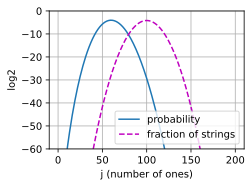

In [8]:
d2l.plot(j, [log2_prob_j, log2_count - n], 'j (number of ones)', 'log2',
         legend=['probability', 'fraction of strings'],
         ylim=[-60, 0])

The two curves peak far apart. The probability of having $j$ ones peaks at
$j = 60$, where the messages are a fraction $2^{-28}$ of all strings. The
fraction of strings peaks at $j = 100$, where the probability is $2^{-29}$.
The single most probable message, at $j = 0$, has probability $2^{-103}$ and
falls off the chart. The typical messages are neither the most probable
messages nor the most numerous ones. They sit where the number of messages
times the probability of each is largest.

The typical set serves proofs, and it makes a poor coder. Indexing it costs
$189$ bits for every typical message, $13$ bits above $nH = 176.3$, and the
code fails on one message in a hundred. Arithmetic coding of the same source
with the true model never fails and averages under $nH + 2 = 178.3$ bits by
the equation. What the typical set shows is that a long
message almost surely has the source's composition, and that about $2^{nH}$
messages have that composition.

## Perplexity

Language models rarely report a file size. They report one number on
held-out text, the perplexity, and it is the code length of this section in
another unit.

### Perplexity as a Branching Factor

For a text of $n$ tokens and a model with next-token probabilities
$q(\cdot \mid x_{<i})$, the loss per token in nats and its exponential, the
*perplexity* [@Jelinek.Mercer.Bahl.ea.1977], are

$$
\textrm{CE} = -\frac{1}{n}\sum_{i=1}^n \log q(x_i \mid x_{<i}),
\qquad
\textrm{PPL} = \exp(\textrm{CE})
= \Big(\prod_{i=1}^n q(x_i \mid x_{<i})\Big)^{-1/n}.
$$

Written without arguments, $\textrm{CE}$ is the loss of the model on this
one text, and its expectation over texts is a cross-entropy between source
and model. The second form of the perplexity is an inverse geometric mean
of probabilities. that section introduces perplexity and
reads it as an *effective branching factor*: a model that is uniformly
undecided among $k$ tokens at every step has perplexity $k$, and a perfect
model of a deterministic sequence has perplexity $1$.

The output of that section shows the reading on real
text, with characters as tokens. A model that knew nothing would hesitate
among all $27$ symbols. The letter frequencies alone bring the perplexity
down to $16.91$, about $17$ equally likely symbols, and three characters of
context bring it to $5.84$: the model is then, on average, about as
uncertain of the next character as of the roll of a die. The cell computes
perplexity as $2$ to the power of the bits per character, and $e$ to the
power of the nats gives the same values, because
$\textrm{PPL} = b^{\textrm{CE}_b}$ for the cross-entropy $\textrm{CE}_b$ in
any log base $b$
(Exercise 11).

### The Perplexity Floor

Perplexity has a floor. For a stationary source it is the exponentiated
entropy rate, and it holds only in expectation. The loss is in nats and the
entropy rate $H_{\textrm{rate}}$ of the equation is in
bits, hence the factor $\ln 2$.

**Proposition (perplexity floor).** *Let the text $X_1, \ldots, X_n$ come
from a stationary source, let $q$ be any model, and let $\textrm{CE}$ and
$\textrm{PPL}$ be the loss and the perplexity
the equation of this text under $q$. Then*

$$
\mathbb{E}[\textrm{CE}] \geq H_{\textrm{rate}} \ln 2,
\qquad
\mathbb{E}[\textrm{PPL}] = \mathbb{E}\big[e^{\textrm{CE}}\big] \geq 2^{H_{\textrm{rate}}}.
$$

**Proof.** Fix a prefix $x_{<i}$. The expected loss of the model on the
next token is a cross-entropy between the source's conditional
distribution $p(\cdot \mid x_{<i})$ and the model's, and by Gibbs'
inequality it is at least the entropy of the source's conditional
distribution. Averaging over prefixes gives
$\mathbb{E}[-\log q(X_i \mid X_{<i})] \geq \mathbb{E}[-\log p(X_i \mid
X_{<i})]$. The log-probability of a text is the sum of its next-token
log-probabilities, $\log p(x_{1:n}) = \sum_i \log p(x_i \mid x_{<i})$, so
summing over $i$ and dividing by $n$ gives $\mathbb{E}[\textrm{CE}] \geq
\tfrac{\ln 2}{n} H(X_1, \ldots, X_n) \geq H_{\textrm{rate}} \ln 2$, the
last step by the monotone decrease of the block entropy per symbol.
Finally, $e^x$ is convex, so its average lies above its value at the
average (Jensen's inequality):
$\mathbb{E}[e^{\textrm{CE}}] \geq e^{\mathbb{E}[\textrm{CE}]}
\geq 2^{H_{\textrm{rate}}}$. $\blacksquare$

No model can be less perplexed, on average, than the source's own
randomness allows. If English has Shannon's one bit per character, the
floor for a character model is a perplexity of $2$, one coin flip per
letter, and the counting model's $5.84$ is far above it.

The proposition bounds an expectation, and the perplexity of a single short
text can fall below the floor. A source that emits `a` with probability
$0.9$ has $2^H = 1.38$, yet its own true model scores a text of ten symbols
below that whenever the text contains no `b`, which happens with
probability $0.9^{10} = 35\%$. A long text from this source still lands
below $2^H$ almost half the time, but by a margin that shrinks with its
length (Exercise 10). In
general, for an ergodic source and the true model, the perplexity of one
long text converges to $2^{H_{\textrm{rate}}}$ as $n \to \infty$, a fact we
grant.

### Perplexity across Tokenizers

Perplexity is computed per token, so it depends on the tokenizer, and two
models are comparable by perplexity only under one tokenizer.
that section shows this on three tokenizers and repairs
it by dividing the total surprisal by the number of bytes of the text. In
the terms of this section the repair is a code length per unit of text. A
text of $n_{\textrm{char}}$ characters split into $n_{\textrm{tok}}$ tokens
costs $n_{\textrm{tok}} \log_2 \textrm{PPL}$ bits, so

$$
\textrm{bpc} = \frac{n_{\textrm{tok}}}{n_{\textrm{char}}}\, \log_2 \textrm{PPL},
$$

and the denominator now depends on the text alone. Where every character
is one byte, as in our 27-symbol text, bits per character are the main
text's bits per byte.

A perplexity, like every code length in this section, needs a model whose
probability for each symbol the encoder and the decoder can both evaluate.
Two distributions known only through samples, such as a generator's
samples and the data, give no code to measure.
that section and
that section build comparisons that work from
samples.

## Summary

There is a code whose length is a model's log-loss, so a loss is a file
size. A symbol code must round every codeword to whole bits, and its best
expected length lies between $H_2(P)$ and $H_2(P) + 1$ bits. Arithmetic
coding rounds once per message: it stores a message in its total surprisal
under any next-symbol model, a language model included, plus at most two
bits, so a model $Q$ costs the cross-entropy and the KL divergence is its
excess over the true model. Real compressors compete with models on these
terms. On *The Time Machine* a counting model with three characters of
context beats `zlib` and a fourth character makes it worse, because the
cost of learning a model is part of its code length, which is the rule by
which MDL chooses between models. For a source with memory no code averages
fewer bits per symbol than the entropy rate, and a perplexity is that code
length exponentiated: at least $2^{H_{\textrm{rate}}}$ in expectation, and
comparable across models only under one tokenizer.

## Exercises

1. **Questions as codewords.** A friend draws one of $k$ outcomes from a
   known distribution $P$, and you identify it with yes/no questions. Each
   question may depend on the answers so far.
    1. Show that every such strategy is a prefix-free code, with the list
       of answers as the codeword, and that every prefix-free code is a
       strategy. Use the Kraft inequality the equation to show
       that no strategy identifies every one of $k$ outcomes within $m$
       questions unless $k \leq 2^m$. How many objects can the parlor game
       of twenty questions tell apart?
    1. *Guessing* asks "Is it outcome $1$?", then "Is it outcome $2$?", and
       so on, most probable outcome first. Find its codeword lengths. Show
       that it needs $1.75$ questions on average for the dyadic source,
       which is the entropy, and $(k+1)/2 - 1/k$ questions for $k$ equally
       likely outcomes. For $k = 8$, name a strategy that needs fewer.

1. **McMillan's theorem.** A code is uniquely decodable if every
   concatenation of codewords parses in only one way.
    1. Show that the code $\{0, 01, 011\}$ is uniquely decodable but not
       prefix-free, and check that it satisfies the Kraft inequality.
    1. Prove that every uniquely decodable code satisfies the Kraft
       inequality the equation. Hint: expand
       $\big(\sum_i 2^{-\ell_i}\big)^m$ as a sum over all strings of $m$
       codewords of $2^{-(\textrm{total length})}$, and group the strings
       by their total length $L$, where $m \leq L \leq m \ell_{\max}$.
       Unique decodability allows at most $2^L$ strings of total length
       $L$, so the sum is at most $m \ell_{\max}$. Take $m$-th roots and let
       $m \to \infty$.

1. **Huffman codes.** Huffman's algorithm [@Huffman.1952] builds a
   prefix code by repeatedly merging the two least probable symbols into
   one symbol of their summed probability, and then assigning $0$ and $1$
   to the two members of each merge.
    1. Run it on $P = (0.6, 0.3, 0.1)$ and on $(0.4, 0.3, 0.2, 0.1)$. Report
       the codeword lengths and the expected length of each code, next to
       the Shannon code and $H_2$.
    1. Prove that Huffman's code has the smallest expected length of all
       prefix codes. First show that in an optimal code $p_i > p_j$ implies
       $\ell_i \leq \ell_j$, and that the two longest codewords have the
       same length and can be taken to be siblings in the tree. Then show
       that merging the two least probable symbols $i, j$ reduces the
       problem by one symbol with
       $\mathbb{E}[\ell] = \mathbb{E}[\ell'] + p_i + p_j$, where $\ell'$
       are the lengths of the merged code. Conclude by induction.
       Hint: exchange two codewords and compare the expected lengths.
    1. For the source that emits `a` with probability $0.9$,
       show that every symbol code spends at least one bit per symbol. Then
       code *pairs* of symbols as a four-symbol source with Huffman's
       algorithm and check the text's $0.645$ bits per original symbol. Do
       the same for triples. How does the slack over the entropy compare
       with the bound $1/n$ in each case?
    1. The guessing strategy of Exercise
       1 is the code with
       lengths $1, 2, \ldots, k-1, k-1$. Sort the probabilities,
       $p_1 \geq \cdots \geq p_k$, and show that Huffman's algorithm can
       return these lengths whenever $p_i \geq \sum_{j > i} p_j$ for every
       $i$, so that guessing is then a best strategy. The source
       $(0.4, 0.3, 0.2, 0.1)$ violates the condition. Is guessing a best
       strategy for it?

1. **Where the slack goes.** A code with lengths $\ell_i$ spends
   $Z = \sum_i 2^{-\ell_i} \leq 1$ of its budget and implies the
   distribution $q_i = 2^{-\ell_i}/Z$, and the equation
   writes $\mathbb{E}[\ell] - H_2(P) = D_{\textrm{KL}}^{(2)}(P\|Q) -
   \log_2 Z$.
    1. The text splits the waste of the Shannon code of
       $P = (0.6, 0.3, 0.1)$ into $0.005$ bits of mismatch and $0.300$ of
       unspent budget. Check the split by computing $Z$ and $Q$ for its
       lengths $1, 2, 4$, and do the same for Huffman's lengths $1, 2, 2$.
       Which code wastes bits on unspent budget, and which on mismatch?
    1. Two codes are built from the model $Q = (0.2, 0.5, 0.3)$ and used on
       data from $P$: the Shannon code, with lengths $3, 1, 2$, and
       Huffman's, with lengths $2, 1, 2$. Split the excess of each over
       $H_2(P)$ into the two terms. The distribution implied by the Shannon
       code is further from $P$ than $Q$ itself, for which
       $D_{\textrm{KL}}^{(2)}(P\|Q) = 0.571$ bits. Which symbol is
       responsible?
    1. Show that the Shannon code of any $P$ leaves less than one bit
       unspent, $-\log_2 Z < 1$, and that it leaves nothing unspent only
       when every probability is a power of $\tfrac12$.

1. [code] **Exact arithmetic coding.** ● The interval narrowing of
   that section stores `lo` and `hi` as
   floating-point numbers. Draw a message of $n = 1000$ symbols, each of
   which is `a` with probability $0.9$ and `b` otherwise.
    1. Run the floating-point narrowing on this message with the model
       $q(\texttt{a}) = 0.9$. After how many symbols does `hi - lo` first
       differ from the product of the probabilities by more than $0.1\%$,
       and after how many does it become zero? Relate both answers to the
       $53$-bit significand of a double-precision number.
    1. Repeat the narrowing with exact rationals (`fractions.Fraction`).
       Name a point of the final interval as the text's cell does, write a
       decoder that replays the model to recover the message, and compare
       the code length with the surprisal of the message and with
       $n H_2(0.9, 0.1)$.
    1. Encode the same message with the mismatched model
       $q(\texttt{a}) = 0.7$. Compare the increase in code length with
       $n D_{\textrm{KL}}^{(2)}(P \| Q)$. Why do the two numbers differ for
       a single message?

1. [extended] **Adaptive context-model compression.** ●● The text's
   `adaptive_bits` is a complete description length in the sense of
   the equation, with the cost of learning the model inside it.
   By the equation, an arithmetic coder driven by its
   predictions spends at most two bits more. @Blier.Ollivier.2018
   use such prequential codes to measure the description length of deep
   networks.
    1. Extend the text's experiment to $m = 0, 1, \ldots, 8$. For each $m$,
       compare the adaptive code length with the per-character
       cross-entropy of the order-$m$ model whose counts are taken from the
       entire text, and with `zlib`.
    1. Explain why the adaptive code length has a minimum over $m$ while
       the cross-entropy of the fitted model keeps falling. Which order does
       MDL select? Which term of the equation does the cross-entropy
       of the fitted model leave out?
    1. Design an adaptive model that combines contexts of several orders,
       for example by falling back to shorter contexts when a long context
       has few counts. Report a table of bits per character for every model
       you tried, together with `zlib`, and a paragraph on the design choice
       that mattered most.

1. **Two-part code for a coin.** ● A sequence $\mathcal{D}$ of $n$ coin
   flips contains $j$ heads, and $\hat\theta = j/n$. Hypothesis
   $\mathcal{M}_0$ is the fair coin: it has no parameter to describe, and
   $L(\mathcal{D} \mid \mathcal{M}_0) = n$ bits. Hypothesis
   $\mathcal{M}_1$ is a coin with bias $\theta$. Its encoder sends the point
   $\theta_q$ nearest to $\hat\theta$ on a grid of spacing $\Delta$ in
   $(0, 1)$, which costs $L(\mathcal{M}_1) = \log_2(1/\Delta)$ bits, and the
   decoder knows $n$ and $\Delta$.
    1. Use the decomposition the equation to show that
       $L(\mathcal{D} \mid \mathcal{M}_1) = n H_2(\hat\theta, 1 - \hat\theta)
       + n D_{\textrm{KL}}^{(2)}(\hat\theta \,\|\, \theta_q)$, where the KL
       divergence is that of the Bernoulli distributions with these
       parameters. In nats, this KL divergence is
       $(\theta_q - \hat\theta)^2 / \big(2\hat\theta(1 - \hat\theta)\big)$
       to second order. Derive the expansion, and show that the total
       length the equation of $\mathcal{M}_1$ exceeds
       $n H_2(\hat\theta, 1 - \hat\theta)$ by at most about
       $\log_2(1/\Delta) + n\Delta^2 /
       \big(8\hat\theta(1 - \hat\theta) \ln 2\big)$ bits.
    1. Which spacing $\Delta$ minimizes this bound? The decoder must know
       $\Delta$ before it decodes $\theta_q$. Why can the code therefore not
       use the minimizer? Show that the spacing $\Delta = 1/\sqrt{n}$, which
       depends on $n$ alone, gives an excess of
       $\tfrac{1}{2}\log_2 n + O(1)$ bits whenever $\hat\theta$ stays
       bounded away from $0$ and $1$.
    1. Take $n = 1000$ and the approximation
       $L(\mathcal{M}_1) + L(\mathcal{D} \mid \mathcal{M}_1) \approx
       n H_2(\hat\theta, 1 - \hat\theta) + \tfrac{1}{2}\log_2 n$ bits. The
       text showed that $\mathcal{M}_1$ wins at $j = 600$ by $24$ bits.
       Which hypothesis wins at $j = 520$? Approximately how far from $n/2$ must $j$ lie for
       $\mathcal{M}_1$ to win, and how many standard deviations $\sqrt{n}/2$
       of $j$ under the fair coin is that?

1. **Entropy rate of a two-state chain.** A chain on $\{\texttt{a},
   \texttt{b}\}$ moves from `a` to `b` with probability $0.1$ and from `b`
   to `a` with probability $0.3$, and it starts from its stationary
   distribution.
    1. Find the stationary distribution and $H(X_1)$ in bits.
    1. Show that $H(X_n \mid X_{n-1}) = \sum_s \pi_s H_2(r_s, 1 - r_s)$
       bits, where $\pi$ is the stationary distribution and $r_s$ is the
       exit probability of state $s$, and that the entropy rate equals this
       value. Compute it.
    1. Show that $\tfrac1n H(X_1, \ldots, X_n) = \tfrac1n\big(H(X_1) +
       (n-1) H_{\textrm{rate}}\big)$ and that it decreases to
       $H_{\textrm{rate}}$.
    1. Consider two limits. With both exit probabilities equal to
       $\tfrac12$ the chain is i.i.d. and the rate is $1$ bit. With both
       exit probabilities equal to $r$, the rate tends to $0$ as $r \to 0$,
       while $H(X_1)$ stays at $1$ bit. What does $H(X_1)$ say about how
       well the chain compresses?
    1. [code] Simulate $10^5$ steps of the first chain and code them with
       the text's `adaptive_bits` at orders $0$, $1$ and $2$. Which orders
       reach the rate, and what does the order-$0$ length converge to?

1. [code] **Typical and high-probability sets.** ● The code of
   that section declares a binary string of length $n = 200$
   from a Bernoulli source with $p = 0.3$ typical when its surprisal per
   symbol lies within $\delta = 0.1$ bit of the entropy $H$ in bits. It
   finds $2^{188.8}$ typical strings, inside the bounds
   $0.989 \cdot 2^{156.3} \leq |A_\delta| \leq 2^{196.3}$ of the AEP
   proposition and well above $2^{nH} = 2^{176.3}$.
    1. Which string is the most probable one? Compute its surprisal per
       symbol and decide whether it is typical. Why does this string not
       matter for compression?
    1. Let $A$ be the typical set and let $B$ be any set of strings with
       $P(B) \geq 1 - \eta$. Show that
       $P(A \cap B) \geq 1 - \eta - P(A^c)$, and conclude that
       $|B| \geq \big(1 - \eta - P(A^c)\big)\, 2^{n(H - \delta)}$.
    1. The smallest set with probability at least $0.9$ collects strings in
       order of decreasing probability. Group the strings by their number
       $j$ of ones, as the code does, and compute $\tfrac{1}{n}\log_2$ of
       the size of this set for $n = 200$, $1000$, $5000$, and $20000$.
       Compare it with $H$ and with $\tfrac{1}{n}\log_2 |A_\delta|$ at the
       same $n$. Which of the two sets grows like $2^{nH}$, and why does
       the typical set with a fixed $\delta$ not?

   *Adapted from David Tse,
   [EE376A/Stats376A: Information Theory, Homework 2](https://web.stanford.edu/~kedart/ee376a_winter1617/hw2.pdf),
   Problem 6.*

1. **The perplexity floor.**
    1. A Bernoulli source emits `a` with probability $0.9$ and `b`
       otherwise, and its own true model scores a text of $n$ symbols.
       Write the loss $\textrm{CE}$ of the equation as a
       function of the number $j$ of `b`'s and show that
       $\textrm{PPL} < 2^{H}$ exactly when $j < n/10$. The text gives the
       probability of this event for $n = 10$. Compute it for $n = 100$
       and $n = 1000$. What does it tend to, and how does the typical
       distance of $\textrm{PPL}$ from $2^H$ change with $n$?
    1. A leaderboard reports one perplexity on one held-out set. Explain why
       the equation does not bound that number, and why a
       *lower* reported perplexity, under the same tokenizer, nevertheless
       always means a smaller total surprisal of that set, which is its
       arithmetic code length to within two bits.

1. **Perplexity across tokenizers.** Perplexity is computed per token, so
   it depends on how a text is split into tokens.
    1. Show that $b^{\textrm{CE}_b}$ is the same number for every log base
       $b$, where $\textrm{CE}_b$ is the per-token cross-entropy in
       base-$b$ units.
    1. Two language models are evaluated on the same text of $10^6$
       characters. The tokenizer of model A splits it into
       $2.5 \times 10^5$ tokens, and A reaches a per-token perplexity of
       $20$. The tokenizer of model B splits it into $6.7 \times 10^5$
       tokens, and B reaches a per-token perplexity of $8$. Convert both
       results to bits per character with the equation. Which model
       predicts the text better?
    1. Take the entropy rate of the text to be one bit per character, the
       estimate of @Shannon.1951 . By the equation the
       expected per-token perplexity is at least $2^{H}$, where $H$ is the
       entropy rate per *token* in bits. What is the lowest perplexity any
       model can reach in expectation with the tokenizer of A, and with
       that of B? How far is each model from its floor?
    1. Explain in two sentences why the two perplexities cannot be compared
       directly while the two values of bits per character can.

[Discussions](https://d2l.discourse.group/t/36865)